## Module 2: FSHD Clinical Trial Project


## Project Goal:

The problem that our group is addressing is Facioscapulohumeral muscular dystrophy(FSHD), which is a disease that leads to progressive muscle degeneration due to overexpression of the DUX4 gene in muscle cells. Finding a solution to this problem matters because individuals with FSHD experience a variety of different damaging trajectories that all involve a decline in function and can severely affect the quality of their lives. 

Using natural history data, we identified candidate measures to include as exploratory endpoints, which are muscle fat fraction (FF) and dorsiflexion quantitative muscle testing (QMT) because both are expected to worsen as FSHD progresses (FF goes up as muscle is replaced by fat, and QMT goes down as the muscle gets weaker), making them relevant measures for illustrating disease progression. We also identified those biomarkers as good exploratory measures because current clinical trials focus on MRI fat fraction and muscle strength (like QMT), conveying the idea that they are already established as useful endpoints. They are also useful as endpoints because they track two different types of changes in muscle: structural and functional. Muscle fat fraction is a quantitative measure of how much muscle is taken up by fat, while dorsiflexion quantitative muscle testing indicates the force that can be produced by an individual's muscles. 

Our team is asking whether muscle FF or dorsiflexion QMT are more sensitive to disease progression in candidates over a period of about two years. This question matters for developing and evaluating treatments in clinical trials because, by revealing which measure is more sensitive to degeneration, we can more easily identify the efficacy of a treatment in delaying or healing FSHD.


## Disease Background: 

**Prevalence & incidence**
- FSHD is one of the most common muscular dystrophies. Estimates range from about 1 in 8,000 to 1 in 20,000 people, and a Dutch population study found roughly 12 cases per 100,000.
- Men and women are both affected, and most people start noticing symptoms in their teens or early twenties.
- Many mildly affected people are never diagnosed, so the true number is probably higher than reported. ([Deenen et al., 2014, *Neurology*](https://doi.org/10.1212/WNL.0000000000000797))

**Symptoms**
- Weakness usually shows up first in the face (trouble smiling, whistling, or fully closing the eyes) and the shoulders, where the shoulder blades stick out ("winging") and lifting the arms gets hard.
- It then tends to move to the upper arms, stomach muscles, and lower legs. Weakness in the tibialis anterior (TA) causes foot drop, which is why our project looks at this muscle.
- The weakness is often uneven between the left and right sides, and many patients also deal with chronic pain, fatigue, and sometimes hearing loss or retinal blood vessel problems. ([Statland & Tawil, 2016, *Continuum*](https://doi.org/10.1212/CON.0000000000000402))

**Diagnosis**
- Doctors usually suspect FSHD from the pattern of weakness and family history, then confirm it with a genetic test.
- About 95% of patients have FSHD1, where the D4Z4 repeat region on chromosome 4 is shortened to 1–10 repeats. The other ~5% have FSHD2, usually caused by a mutation in the *SMCHD1* gene.
- MRI, EMG, and muscle biopsy can support the diagnosis, but genetic testing has mostly replaced biopsy. ([GeneReviews: FSHD](https://www.ncbi.nlm.nih.gov/books/NBK1443/))

**Standard of care treatments (& reimbursement)**
- There is no FDA-approved treatment that slows or stops FSHD, so care focuses on managing symptoms.
- This includes physical and occupational therapy, low-to-moderate aerobic exercise, ankle-foot braces for foot drop, and pain management. Some patients get surgery to fix the shoulder blade to the ribs (scapular fixation).
- Braces, therapy, and mobility aids are usually covered by insurance or Medicare when medically necessary, but coverage and out-of-pocket costs vary a lot between plans. ([Tawil et al., 2015, AAN guideline, *Neurology*](https://doi.org/10.1212/WNL.0000000000001783))

**Disease progression & prognosis**
- FSHD gets worse slowly, and how fast it progresses varies a lot, even between relatives with the same mutation.
- About 20% of patients eventually need a wheelchair, but most people have a normal life expectancy.
- As the disease progresses, muscle is gradually replaced by fat, which MRI can measure as an increasing fat fraction. ([Statland & Tawil, 2016, *Continuum*](https://doi.org/10.1212/CON.0000000000000402))

**Biological mechanisms**
- In healthy adult muscle, the *DUX4* gene inside the D4Z4 repeats is switched off. When the repeats are shortened (FSHD1) or *SMCHD1* is mutated (FSHD2), the region opens up and *DUX4* gets turned on.
- DUX4 is a transcription factor that switches on genes normally only used in early embryos. In muscle cells this leads to oxidative stress, inflammation, and cell death.
- Over time, damaged muscle fibers are replaced by fat and scar tissue, which is the change we measure as fat fraction on MRI. ([Tawil et al., 2014, *Skeletal Muscle*](https://doi.org/10.1186/2044-5040-4-12))

**Clinical trials/next-gen therapies**
- Most new therapies try to block DUX4 directly. Examples include del-brax (Avidity), an antibody linked to an RNA drug, and ARO-DUX4 (Arrowhead), which uses RNA interference.
- Losmapimod, a pill meant to lower DUX4 levels, failed to improve its main outcome in a Phase 3 trial in 2024.
- These trials track MRI fat fraction, muscle strength (like QMT), and DUX4-related biomarkers, which are the kinds of measures our project compares. ([ClinicalTrials.gov NCT05747924](https://clinicaltrials.gov/study/NCT05747924))


## Data Set:

**Subject and timepoints**
- We analyzed one FSHD participant.
- They were scanned at two visits: TP1 (baseline) and TP2 (follow-up).
- Having the same person at two visits lets us look at how their muscle changed over time instead of comparing different people. (FSHD_TA_MRI_example_notebook.ipynb)

**Tibialis anterior MRI data**
- The images are cross-sections of the lower leg focused on the tibialis anterior, the muscle on the front of the shin that lifts the foot.
- The MRI slices are from the subject's **left** TA (per the dataset README).
- We used it because it is often affected early in FSHD and its weakness causes foot drop.
- Each slice is saved as a 2D array of 266 × 224 pixels. ([Wang et al., 2019, *Neurology*](https://doi.org/10.1212/WNL.0000000000006836))

**Water- and fat-image files**
- Each slice has a pair of files saved as NumPy arrays.
- They come from a Dixon MRI scan, which splits the signal into a water image (mostly healthy muscle) and a fat image (fat that has replaced muscle).
- Because both images show the same slice, they line up pixel for pixel, so we can combine them to calculate fat fraction. (FSHD_TA_MRI_example_notebook.ipynb)

**TA segmentation mask**
- Each slice also has a yes/no map where 1 means the pixel is part of the TA and 0 means it isn't.
- The mask lets us ignore bone, other muscles, and background so only TA pixels go into our results.
- The masks came already drawn with the dataset, so we did not segment the muscle ourselves. (FSHD_TA_MRI_example_notebook.ipynb)

**Sampled locations along the muscle**
- There are 8 slices per visit (16 total), taken at 10%, 20%, and so on up to 80% of the TA's length.
- slice_info.csv gives each slice's position as both a percentage and a distance in mm from the top of the muscle.
- The slices are not evenly spaced (about 20–28 mm apart, spanning 24–184 mm at TP1 and 24–196 mm at TP2), so we plot using real distance instead of percent. (FSHD_TA_MRI_example_notebook.ipynb)

**Meaning and units of the image signals**
- The water and fat values are MRI signal intensities in arbitrary units, so a single value doesn't mean much by itself.
- To get something meaningful, we compute fat fraction = fat / (water + fat) × 100. A pixel at 0% is all muscle and one at 100% is all fat.
- For example, the TP1 slice at 40% of the muscle has 360 TA pixels with an average fat fraction of about 30%.(FSHD_TA_MRI_example_notebook.ipynb)

**Clinical, biomarker, and functional measurements**
- From the MRI, we get TA fat fraction for each slice at each visit, which tells us about the muscle's structure.
- We compare this with dorsiflexion quantitative muscle testing (QMT), which measures how hard the person can pull their foot up and reflects how well the TA works. FF and QMT for 34 subjects (both legs, at baseline, Year 1, and Year 2) come from `Module2_FSHD_Dataset (1).csv`.
- The larger study this data comes from also collected clinical severity scores and muscle biopsies that measured DUX4-related gene activity. ([Wang et al., 2019, *Neurology*](https://doi.org/10.1212/WNL.0000000000006836))

**Source of the data**
- The data was given to us by the BME 2315 instructors in the folder FSHD_TA_MRI_data_0020_TP1_TP2.
- It is a de-identified piece of an FSHD natural-history MRI study from the University of Washington, which followed patients over time without giving them treatment.
- The images and masks were already converted into .npy files, so we could load them straight into Python. ([Wang et al., 2021, *Ann Clin Transl Neurol*](https://doi.org/10.1002/acn3.51440))

**How the MRI data and mask were generated**
- Participants were scanned on a clinical MRI machine with a Dixon sequence, which produces separate water and fat images in one scan.
- Trained readers then traced the TA on the images to make the masks.
- For this project, slices were chosen at set percentages along the TA and exported with the masks. ([Wang et al., 2019, *Neurology*](https://doi.org/10.1212/WNL.0000000000006836))


## MRI Data Analysis Methodology:


To analyze the FSHD data, we began by loading the water, fat, and segmentation-mask files. This involved importing packages such as numpy, pandas, and matplotlib and setting the data folder to DATA_DIR, a relative path to the `FSHD_TA_MRI_data_0020_TP1_TP2` folder saved in our GitHub repository so the notebook runs on any computer. We read slice_info.csv with pandas. 

In [1]:
# Import the packages used throughout the MRI analysis
from pathlib import Path          # builds file paths that work on any operating system
import numpy as np                # array math for the image data
import pandas as pd               # reads and organizes tables (CSV files)
import matplotlib.pyplot as plt   # plotting

# Folder that holds the subject UW_0020 MRI data (water, fat, and mask .npy files + slice_info.csv)
# Relative path: the data folder is stored in the repository next to this notebook
DATA_DIR = Path("FSHD_TA_MRI_data_0020_TP1_TP2")

# slice_info.csv lists every slice: its visit, location along the muscle, and matching file names
manifest = pd.read_csv(DATA_DIR / "slice_info.csv")
manifest

,subject,timepoint,slice_id,percent_along_muscle,z_index,distance_from_muscle_start_mm,water_file,fat_file,mask_file
0,UW_0020,TP1,1,10,41,24.0,TP1_slice_01_water.npy,TP1_slice_01_fat.npy,TP1_slice_01_mask.npy
1,UW_0020,TP1,2,20,46,44.0,TP1_slice_02_water.npy,TP1_slice_02_fat.npy,TP1_slice_02_mask.npy
2,UW_0020,TP1,3,30,52,68.0,TP1_slice_03_water.npy,TP1_slice_03_fat.npy,TP1_slice_03_mask.npy
3,UW_0020,TP1,4,40,58,92.0,TP1_slice_04_water.npy,TP1_slice_04_fat.npy,TP1_slice_04_mask.npy
4,UW_0020,TP1,5,50,64,116.0,TP1_slice_05_water.npy,TP1_slice_05_fat.npy,TP1_slice_05_mask.npy
5,UW_0020,TP1,6,60,69,136.0,TP1_slice_06_water.npy,TP1_slice_06_fat.npy,TP1_slice_06_mask.npy
6,UW_0020,TP1,7,70,75,160.0,TP1_slice_07_water.npy,TP1_slice_07_fat.npy,TP1_slice_07_mask.npy
7,UW_0020,TP1,8,80,81,184.0,TP1_slice_08_water.npy,TP1_slice_08_fat.npy,TP1_slice_08_mask.npy
8,UW_0020,TP2,1,10,40,24.0,TP2_slice_01_water.npy,TP2_slice_01_fat.npy,TP2_slice_01_mask.npy
9,UW_0020,TP2,2,20,46,48.0,TP2_slice_02_water.npy,TP2_slice_02_fat.npy,TP2_slice_02_mask.npy


Next, we loaded a single sample using `slice_info.csv` which has rows named water_file, fat_file, and mask_file for a single slice. Arrays were loaded using np.load and the mask was set to a boolean array. 

In [2]:
# Pick one representative slice: the 4th TP1 slice (40% along the muscle)
row = manifest[manifest["timepoint"] == "TP1"].iloc[3]  # representative mid-muscle slice

# Load the three arrays that belong to this slice
water = np.load(DATA_DIR / row["water_file"])                 # water signal image
fat = np.load(DATA_DIR / row["fat_file"])                     # fat signal image
mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)      # True = TA pixel, False = everything else

# Check that all three arrays line up pixel-for-pixel and count the TA pixels
print("Water image shape:", water.shape)
print("Fat image shape:", fat.shape)
print("Mask shape:", mask.shape)
print("Number of muscle pixels:", mask.sum())

Water image shape: (266, 224)
Fat image shape: (266, 224)
Mask shape: (266, 224)
Number of muscle pixels: 360


Then, we calculated the fat fraction for that single sample, meaning the fraction for every pixel in that sample. We started by setting the denominator of the fraction to be the sum of water and fat. We only included values where the denominator is greater than zero and set pixels where water + fat = 0 to have percentages of 0. Then, we calculated the fat fraction by dividing the fat by the denominator and multiplying by 100 to get the percentage. 

Then we kept a copy, fat_fraction_full, for each pixel to later analyze the whole supplied image region. The mask marked TA pixels as true and anything outside of the muscle as false. After, we created an additional copy for muscle specific analysis called fat_fraction_masked which involved setting pixels outside the TA mask to `NaN` so that background is not included in the mean or histogram. 

The next step in muscle analysis was calculating and printing the mean fat fraction in the sample, and the maximum/minimum fat fraction for the pixels using numpy statistical methods. These analyses were done for the TA and the region as a whole. 


In [3]:
# Fat fraction (%) = fat / (water + fat) * 100, calculated for every pixel
denominator = water + fat
valid_pixels = denominator > 0   # avoid dividing by zero in empty background pixels

fat_fraction = np.divide(
    fat,
    denominator,
    out=np.zeros_like(fat, dtype=float),   # pixels with a zero denominator are set to 0%
    where=valid_pixels
) * 100

# Keep the whole supplied image region for the first analysis.
fat_fraction_full = fat_fraction.copy()

# Then apply the TA mask for the muscle-specific analysis.
fat_fraction_masked = fat_fraction.copy()
fat_fraction_masked[~mask] = np.nan   # NaN = ignored by the TA statistics and histogram

# 1D arrays of fat-fraction values for each region
whole_image_values = fat_fraction_full[valid_pixels]
muscle_values = fat_fraction_masked[~np.isnan(fat_fraction_masked)]

# Compare summary statistics for the whole region vs. the TA only
print(f"Whole supplied image region — mean: {np.mean(whole_image_values):.1f}%")
print(f"Whole supplied image region — minimum: {np.min(whole_image_values):.1f}%")
print(f"Whole supplied image region — maximum: {np.max(whole_image_values):.1f}%")
print()
print(f"TA muscle only — mean: {np.mean(muscle_values):.1f}%")
print(f"TA muscle only — minimum: {np.min(muscle_values):.1f}%")
print(f"TA muscle only — maximum: {np.max(muscle_values):.1f}%")


Whole supplied image region — mean: 48.6%
Whole supplied image region — minimum: 0.0%
Whole supplied image region — maximum: 100.0%

TA muscle only — mean: 29.9%
TA muscle only — minimum: 0.5%
TA muscle only — maximum: 90.7%


We can visualize the images, the mask and the fat-fraction map using some simple steps. first find the bounding box of the TA mask by using the where method to find and contain the mask pixels, and the min/max methods or the edges of the muscle. Then we cropped the TA-specific fat-fraction map by creating a smaller array from the fat_fraction_masked array. the subplot function was used to create the row of images, and subsequent axes methods were used to display different components of the images.  

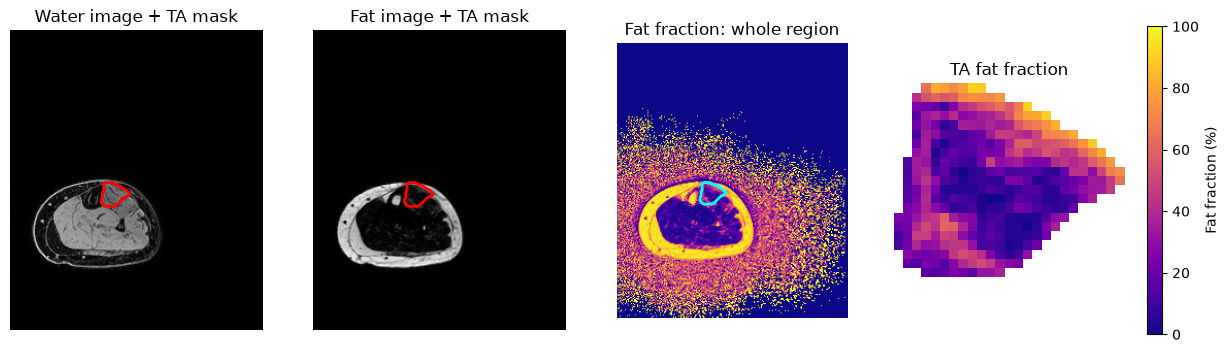

In [5]:
# Find the bounding box of the TA mask
y_pixels, x_pixels = np.where(mask)   # row/column coordinates of every TA pixel

# Edges of the TA (+1 so the last row/column is included when slicing)
y0, y1 = y_pixels.min(), y_pixels.max() + 1
x0, x1 = x_pixels.min(), x_pixels.max() + 1

# Crop the TA-specific fat-fraction map
fat_fraction_TA = fat_fraction_masked[y0:y1, x0:x1]

# One row of four panels
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# Water image with TA mask outline
axes[0].imshow(water, cmap="gray")
axes[0].contour(mask, levels=[0.5], colors="red", linewidths=2)   # draws the mask border
axes[0].set_title("Water image + TA mask")

# Fat image with TA mask outline
axes[1].imshow(fat, cmap="gray")
axes[1].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[1].set_title("Fat image + TA mask")

# Fat fraction for the whole supplied image region
whole_image = axes[2].imshow(
    fat_fraction_full,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[2].contour(mask, levels=[0.5], colors="cyan", linewidths=2)
axes[2].set_title("Fat fraction: whole region")

# Zoomed-in fat fraction for the TA only
ta_image = axes[3].imshow(
    fat_fraction_TA,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[3].set_title("TA fat fraction")

# Hide pixel-number axes since these are images
for ax in axes:
    ax.axis("off")

# Both fat-fraction plots use the same 0–100% scale
fig.colorbar(
    ta_image,
    ax=axes[2:],
    fraction=0.046,
    pad=0.04,
    label="Fat fraction (%)"
)

plt.show()

Figure 1: Visual of the images, the mask, and fat-fraction map for a single slice 
-
This figure shows the water image + red TA mask, the fat image + red TA mask, fat fraction visual for the whole region, and the fat fraction zoomed in. These images are included to illustrate the fat fraction for the TA mask. This figure allows us to conclude that the mask isolates the TA from the surrounding bone, fat, and other muscles, and that fat is unevenly spread inside the TA: most of the muscle is still low in fat, but some regions are heavily fat-replaced (mean 29.9%, maximum 90.7% on this slice). 

Next, we visualized the fat-fraction distribution by creating a histogram of fat-fraction values for the whole region and for TA only. This involved using the previously made fat-fraction value arrays, whole_image_values and muscle_values, to use the correct pixels for distribution.  

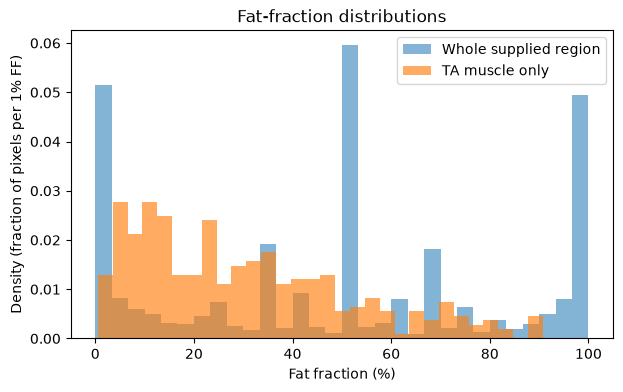

In [6]:
# Overlapping histograms of pixel fat fractions: whole region vs. TA only
# density=True scales each histogram to area 1 so regions with different pixel counts can be compared
plt.figure(figsize=(7, 4))
plt.hist(whole_image_values, bins=30, alpha=0.55, label="Whole supplied region", density=True)
plt.hist(muscle_values, bins=30, alpha=0.65, label="TA muscle only", density=True)
plt.xlabel("Fat fraction (%)")
plt.ylabel("Density (fraction of pixels per 1% FF)")
plt.title("Fat-fraction distributions")
plt.legend()
plt.show()


Figure 2: Fat-Fraction distributions for a single slice
-
This histogram illustrates (as densities, so the two regions can be compared even though the TA has far fewer pixels) overlapping distributions of fat-fraction values for the TA and the region as a whole. The graph is included to show the differences in distribution of fat-fraction percentages for the two regions. We concluded that differences in distributions, shown by the fat fractions being spread mostly between 0–50% with a peak around 5–25% for the TA as opposed to spanning all the values for the whole region, call for specific analysis of the TA for accurate fat fraction values. 

Then, we repeated the analysis for every sampled location in one visit using a for loop to summarize measurements across locations along muscle. The function calculate_fat_fraction() packages the calculation so it can be reused for every row in the selected visit. Statistics such as mean, median, standard deviation, and number of muscle pixels were calculated using np functions: np.nanmean, np.nanmedian, np.nanstd, and mask.sum. The measurements corresponding to their respective locations - which included percent location, distance from muscle starts, and statistics - were stored in a data frame and used to return the locations' fat fraction value.     

In [7]:
def calculate_fat_fraction(water, fat, mask):
    """Return a masked fat-fraction image in percent."""
    denominator = water + fat
    result = np.divide(
        fat,
        denominator,
        out=np.zeros_like(fat, dtype=float),
        where=denominator > 0
    ) * 100
    result[~mask] = np.nan   # keep only TA pixels
    return result

analysis_timepoint = "TP1"  # analyze one visit at a time
analysis_manifest = manifest[manifest["timepoint"] == analysis_timepoint]
results = []   # one dictionary of statistics per slice

# Loop over every slice in the chosen visit
for _, row in analysis_manifest.iterrows():
    # Load this slice's water, fat, and mask arrays
    water = np.load(DATA_DIR / row["water_file"])
    fat = np.load(DATA_DIR / row["fat_file"])
    mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
    ff = calculate_fat_fraction(water, fat, mask)

    # Store the slice location and summary statistics (nan-functions skip non-TA pixels)
    results.append({
        "subject": row["subject"],
        "timepoint": row["timepoint"],
        "slice_id": row["slice_id"],
        "percent_along_muscle": row["percent_along_muscle"],
        "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
        "mean_fat_fraction_percent": np.nanmean(ff),
        "median_fat_fraction_percent": np.nanmedian(ff),
        "std_fat_fraction_percent": np.nanstd(ff),
        "n_muscle_pixels": int(mask.sum()),
    })

# Convert the list of dictionaries into a table (one row per slice)
results_df = pd.DataFrame(results)
results_df

,subject,timepoint,slice_id,percent_along_muscle,distance_from_muscle_start_mm,mean_fat_fraction_percent,median_fat_fraction_percent,std_fat_fraction_percent,n_muscle_pixels
0,UW_0020,TP1,1,10,24.0,83.924382,88.827837,13.272006,61
1,UW_0020,TP1,2,20,44.0,82.706905,86.651582,12.433905,115
2,UW_0020,TP1,3,30,68.0,58.498513,61.821705,22.878862,231
3,UW_0020,TP1,4,40,92.0,29.931733,25.369646,21.584495,360
4,UW_0020,TP1,5,50,116.0,20.866866,14.553991,20.060150,421
5,UW_0020,TP1,6,60,136.0,16.758732,9.049959,19.665424,440
6,UW_0020,TP1,7,70,160.0,17.511838,8.962264,20.456168,388
7,UW_0020,TP1,8,80,184.0,27.873337,22.685185,22.625359,263


We compared fat fraction profiles across two visits by repeating the same calculation for TP1 and TP2. We used physical distance on the x-axis for this and the variables, mean_fat_fraction_percent, percent_along_muscle, and distance_from_muscle_start_mm. The percent location is useful as a reference, but it is not a substitute for the measured spacing. Because the slices for TP2 were taken slightly farther along the muscle than TP1 (up to 12 mm at the same percent), we plotted against distance in mm. 

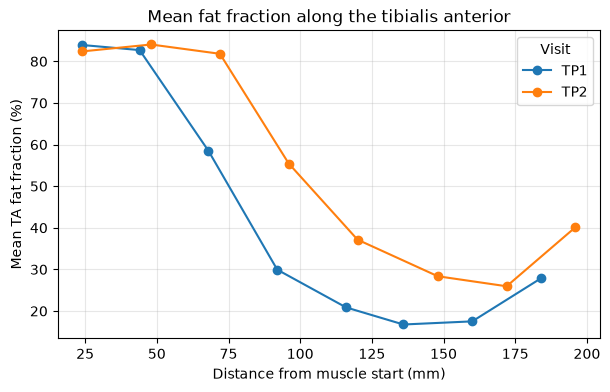

In [8]:
def summarize_visit(timepoint):
    """Return the mean TA fat fraction for every slice in one visit."""
    visit_results = []
    visit_manifest = manifest[manifest["timepoint"] == timepoint]

    for _, row in visit_manifest.iterrows():
        # Load the arrays and calculate the masked fat fraction for this slice
        water = np.load(DATA_DIR / row["water_file"])
        fat = np.load(DATA_DIR / row["fat_file"])
        mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
        ff = calculate_fat_fraction(water, fat, mask)

        visit_results.append({
            "timepoint": timepoint,
            "slice_id": row["slice_id"],
            "percent_along_muscle": row["percent_along_muscle"],
            "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
            "mean_fat_fraction_percent": np.nanmean(ff),
        })

    return pd.DataFrame(visit_results)

# Run the summary for both visits and stack them into one table
profiles_df = pd.concat(
    [summarize_visit("TP1"), summarize_visit("TP2")],
    ignore_index=True
)

# Plot one line per visit: mean TA fat fraction at each slice location
plt.figure(figsize=(7, 4))
for timepoint, group in profiles_df.groupby("timepoint"):
    group = group.sort_values("distance_from_muscle_start_mm")   # order points along the muscle
    plt.plot(
        group["distance_from_muscle_start_mm"],   # physical distance, not percent
        group["mean_fat_fraction_percent"],
        marker="o",
        label=timepoint
    )
plt.xlabel("Distance from muscle start (mm)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Mean fat fraction along the tibialis anterior")
plt.legend(title="Visit")
plt.grid(True, alpha=0.3)
plt.show()


Figure 3: Mean Fat Fraction along the tibialis anterior 
-
This plot shows the mean TA fat-fraction percentage for the two visits, TP1 and TP2, as a function of the distance from the start of the muscle. This is included to demonstrate the differences in fat fractions for 2 visits and allows us to conclude that fat-fraction values are higher at smaller distances from the muscle, but also slightly increase on the outer edges of muscle. We can also conclude that mean fat-fraction values increase at almost all distances for TP2.   

Finally, we saved two reusable summary files: the detailed TP1 statistics (`TA_fat_fraction_summary.csv`) and the mean fat fraction for every slice at both visits (`TA_fat_fraction_profiles_TP1_TP2.csv`), because these CSVs are the type of output that can be used in a larger project analysis. 

In [9]:
# Save the per-slice TP1 statistics so they can be reused in later analysis
output_file = Path("TA_fat_fraction_summary.csv")
results_df.to_csv(output_file, index=False)
print(f"Saved {output_file}")

# Save the mean fat fraction for every slice at both visits (TP1 and TP2)
profiles_file = Path("TA_fat_fraction_profiles_TP1_TP2.csv")
profiles_df.to_csv(profiles_file, index=False)
print(f"Saved {profiles_file}")

Saved TA_fat_fraction_summary.csv
Saved TA_fat_fraction_profiles_TP1_TP2.csv


We also chose to make one more analysis using longitudinal comparison. We ran the analysis once for each visit and compared TP1 and TP2 at the same percent location along the muscle by reshaping the table with `pivot` and subtracting TP1 from TP2. A change in MRI fat fraction may indicate a change in muscle composition, but it is not automatically evidence of improved or worsened patient function. 

In [10]:
# Use the two-visit table if it exists, otherwise fall back to the TP1-only table
comparison_source = profiles_df if "profiles_df" in globals() else results_df

# Reshape so each row is a slice location and each column is a visit
comparison = comparison_source.pivot(
    index="percent_along_muscle",
    columns="timepoint",
    values="mean_fat_fraction_percent"
)

# If both visits are present, calculate the change in mean fat fraction at each location
if {"TP1", "TP2"}.issubset(comparison.columns):
    comparison["change_TP2_minus_TP1"] = comparison["TP2"] - comparison["TP1"]   # positive = more fat at TP2
    display(comparison)
else:
    print("Run the optional two-visit extension before making a longitudinal comparison.")


timepoint,TP1,TP2,change_TP2_minus_TP1
percent_along_muscle,,,
10,83.924382,82.390320,-1.534061
20,82.706905,84.049364,1.342458
30,58.498513,81.815108,23.316595
40,29.931733,55.449853,25.518120
50,20.866866,37.146636,16.279770
60,16.758732,28.351047,11.592316
70,17.511838,25.945668,8.433830
80,27.873337,40.143158,12.269821


Table 1: Change in mean TA fat fraction from TP1 to TP2 at each location
-
This table shows the mean TA fat fraction at each percent location for both visits and the change (TP2 − TP1). It is included to measure how much the muscle changed between visits at each location. We can conclude that fat fraction increased at 7 of 8 locations, with the largest increases in the middle of the muscle (+23.3 at 30% and +25.5 at 40%), while the 10% location, which was already over 80% fat, barely changed (−1.5). This matches Figure 3 and suggests that fat replacement spreads into the parts of the muscle that are not yet fully replaced. One limitation is that TP2 slices sit up to 12 mm farther along the muscle at the same percent, so part of each difference could come from location rather than disease.

## QMT vs. Fat Fraction Analysis:

To answer our project question, we compared TA fat fraction (FF), a structural measure, with dorsiflexion quantitative muscle testing (QMT), a functional measure of how hard a subject can pull their foot up. We used `Module2_FSHD_Dataset.csv`, which has FF and QMT for the right (R) and left (L) TA of 34 subjects at baseline, Year 1, and Year 2. Higher FF means more disease, but **lower** QMT means more disease. We loaded the dataset with pandas and wrote two small helper functions to get the right column for each measure, leg, and visit.


In [11]:
# Packages for the multi-subject FF vs. QMT analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Natural-history dataset: one row per subject (34 subjects), FF and QMT at baseline, Year 1, Year 2
fshd = pd.read_csv("Module2_FSHD_Dataset (1).csv")

visits = ["baseline", "y1", "y2"]
visit_labels = {"baseline": "Baseline", "y1": "Year 1", "y2": "Year 2"}

# Helper functions that return the column name for a leg ("R"/"L") and visit
def ff_col(side, visit):
    return f"ff_{visit}_{side}"

def qmt_col(side, visit):
    return f"dorsiflexion_qmt_{side}_{visit}"

print("Number of subjects:", len(fshd))

Number of subjects: 34


First, we plotted each subject's FF and QMT over time, using the actual months since baseline (`lag_months_baseline`, `lag_months_y1`, `lag_months_y2`) on the x-axis. Each line is one subject, and the right and left legs are shown separately because FSHD is often asymmetric.

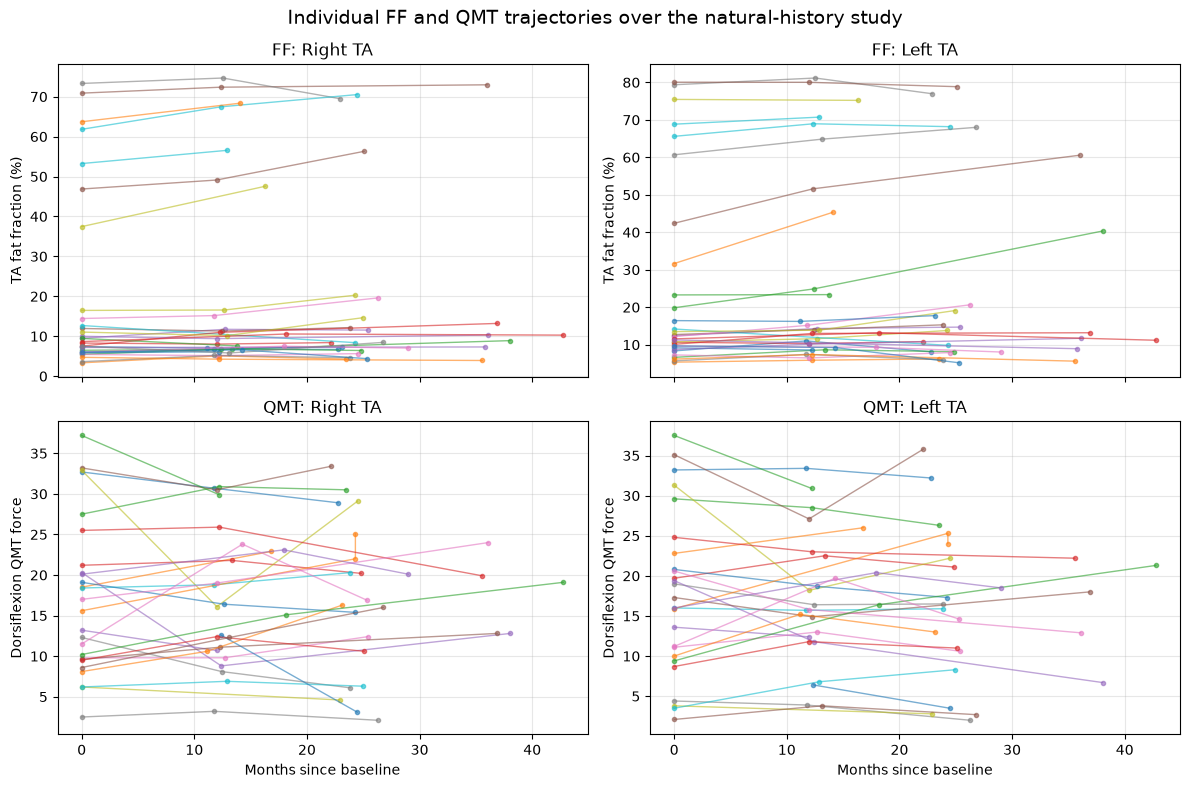

In [12]:
# 2 x 2 grid: rows = measure (FF, QMT), columns = leg (right, left)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
measures = [("FF", ff_col, "TA fat fraction (%)"),
            ("QMT", qmt_col, "Dorsiflexion QMT force")]

for r, (name, col_fn, ylabel) in enumerate(measures):
    for c, side in enumerate(["R", "L"]):
        ax = axes[r, c]
        # Draw one line per subject using their actual visit times
        for _, row in fshd.iterrows():
            months = np.array([row[f"lag_months_{v}"] for v in visits], dtype=float)
            values = np.array([row[col_fn(side, v)] for v in visits], dtype=float)
            keep = ~np.isnan(months) & ~np.isnan(values)   # skip missing visits
            if keep.sum() >= 2:   # need at least 2 visits to draw a line
                ax.plot(months[keep], values[keep], marker="o", markersize=3,
                        linewidth=1, alpha=0.6)
        side_name = "Right" if side == "R" else "Left"
        ax.set_title(f"{name}: {side_name} TA")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)

# Only the bottom row needs x-axis labels (x-axis is shared)
for ax in axes[1]:
    ax.set_xlabel("Months since baseline")

fig.suptitle("Individual FF and QMT trajectories over the natural-history study", fontsize=14)
plt.tight_layout()
plt.show()

Figure 4: Individual FF and QMT trajectories over time
-
This figure shows each subject's TA fat fraction (top) and dorsiflexion QMT force (bottom) at every visit for the right and left legs. It is included to see how each measure changes within the same person over about 2 years. We can conclude that FF lines stay steady or rise slightly and keep the same order between visits, while QMT lines jump up and down with no clear direction, meaning QMT is much noisier from visit to visit than FF.

Next, we calculated each subject's change from baseline (follow-up − baseline) at Year 1 and Year 2, using only subjects who had both visits. Because FF and QMT have different units, we compared them with the **standardized response mean (SRM)** = mean change ÷ standard deviation of the change. A larger SRM means a measure changes more consistently in one direction. We flipped the sign for QMT so that a positive SRM always means worsening (FF going up or strength going down).

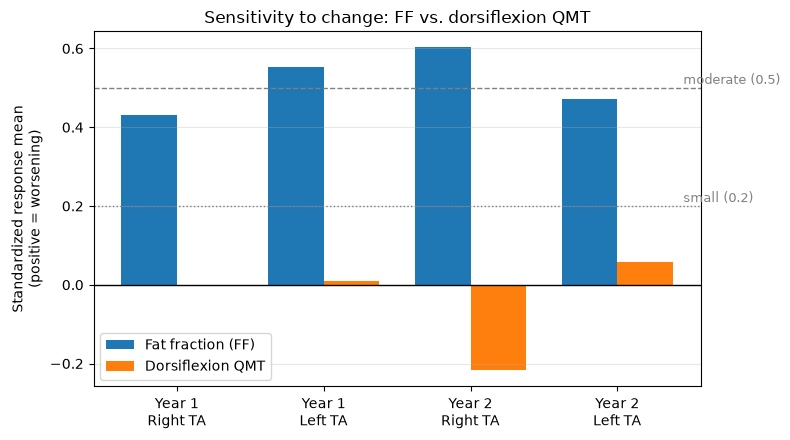

In [13]:
change_rows = []

# Standardized response mean (SRM) for each leg, measure, and follow-up visit
for side in ["R", "L"]:
    # worse_sign flips QMT so a positive SRM always means worsening (FF up, strength down)
    for name, col_fn, worse_sign in [("FF", ff_col, 1), ("QMT", qmt_col, -1)]:
        for visit in ["y1", "y2"]:
            # Within-subject change; dropna keeps only subjects with both visits
            change = (fshd[col_fn(side, visit)] - fshd[col_fn(side, "baseline")]).dropna()
            change_rows.append({
                "measure": name,
                "side": side,
                "visit": visit_labels[visit],
                "n_subjects": len(change),
                "SRM_worsening": worse_sign * change.mean() / change.std(),   # SRM = mean change / SD of change
            })

change_df = pd.DataFrame(change_rows)

# Bar positions: one group per visit/leg, two bars (FF, QMT) per group
groups = [("y1", "R"), ("y1", "L"), ("y2", "R"), ("y2", "L")]
group_labels = [f"{visit_labels[v]}\n{'Right' if s == 'R' else 'Left'} TA" for v, s in groups]
x = np.arange(len(groups))
width = 0.38

def get_srm(name, visit, side):
    """Look up one SRM value from change_df."""
    match = change_df[(change_df["measure"] == name) &
                      (change_df["visit"] == visit_labels[visit]) &
                      (change_df["side"] == side)]
    return match["SRM_worsening"].iloc[0]

ff_srm = [get_srm("FF", v, s) for v, s in groups]
qmt_srm = [get_srm("QMT", v, s) for v, s in groups]

plt.figure(figsize=(8, 4.5))
plt.bar(x - width / 2, ff_srm, width, label="Fat fraction (FF)")
plt.bar(x + width / 2, qmt_srm, width, label="Dorsiflexion QMT")
# Reference lines: 0 = no change, 0.2 = small response, 0.5 = moderate response
plt.axhline(0, color="black", linewidth=1)
plt.axhline(0.2, color="gray", linestyle=":", linewidth=1)
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.text(len(groups) - 0.55, 0.21, "small (0.2)", color="gray", fontsize=9)
plt.text(len(groups) - 0.55, 0.51, "moderate (0.5)", color="gray", fontsize=9)
plt.xticks(x, group_labels)
plt.ylabel("Standardized response mean\n(positive = worsening)")
plt.title("Sensitivity to change: FF vs. dorsiflexion QMT")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Figure 5: Standardized response mean of FF and QMT at each follow-up
-
This bar chart shows the SRM (positive = worsening) for FF and QMT at Year 1 and Year 2 for each leg, with reference lines for a "small" (0.2) and "moderate" (0.5) response. It is included because the SRM puts both measures on the same scale, which directly answers which one is more sensitive to disease progression. We can conclude that FF is more sensitive: its SRMs were 0.43–0.60 in every comparison, while QMT's were all near zero (−0.22 to 0.06), and the negative right-leg value at Year 2 means the average subject actually got slightly stronger.

## Interpolation Analysis:


Following the class interpolation example, we interpolated TA fat fraction **over time** instead of along the muscle. In `Module2_FSHD_Dataset (1).csv`, subjects did not return at exactly 12 and 24 months: Year 1 visits ranged from 11.2 to 24.3 months and Year 2 visits from 22.1 to 42.8 months. Comparing raw Year 2 values would therefore mix subjects followed for 2 years with subjects followed for over 3.5 years. To compare everyone over the same amount of time, we estimated each subject's FF at two common time points:

- **T1** = the earliest Year 1 visit in the group (11.15 months)
- **T2** = the earliest Year 2 visit in the group (22.13 months)

Because every subject's own Year 1 visit is at or after T1 and their Year 2 visit is at or after T2, every estimate falls *inside* that subject's measured data, so this is interpolation and not extrapolation. The inputs are the visit times (`lag_months_baseline`, `lag_months_y1`, `lag_months_y2`) and the FF values (`ff_baseline_R`, `ff_y1_R`, `ff_y2_R`, and the same for the left leg).

In [14]:
from scipy.interpolate import interp1d   # interpolation functions
from scipy import stats                  # statistical tests

# Common time points: the earliest Year 1 and Year 2 visits across all subjects
T1 = fshd["lag_months_y1"].min()
T2 = fshd["lag_months_y2"].min()
print(f"T1 = {T1:.2f} months")
print(f"T2 = {T2:.2f} months")

T1 = 11.15 months
T2 = 22.13 months


We first worked through one subject by hand, the same way as the class example, using subject 13-0004's right TA (visits at 0, 12.3, and 36.9 months). For the **linear** estimate at T1 we used baseline and Year 1 to solve for the line f(x) = a1 + a2·x, by setting up the matrix equation Y = Z·A and solving it with `np.linalg.solve`. For the **quadratic** estimate at T2 we used all three visits to solve for f(x) = a1 + a2·x + a3·x². We then checked both answers with `scipy.interpolate.interp1d`, which should give the same values.

In [15]:
# Worked example: subject 13-0004, right TA
example = fshd.loc[fshd["subject_id"] == "13-0004"].iloc[0]
lag_months = np.array([example[f"lag_months_{v}"] for v in visits], dtype=float)   # x: visit times
ff_values = np.array([example[ff_col("R", v)] for v in visits], dtype=float)       # y: fat fraction
print("lag_months:", lag_months)
print("ff_values: ", ff_values.round(2))

# Linear interpolation at T1 by hand (baseline and Year 1): solve Z·A = Y for A = [a1, a2]
Z_lin = np.array([[1, lag_months[0]],
                  [1, lag_months[1]]])
a_lin = np.linalg.solve(Z_lin, ff_values[:2])
estimate_T1 = a_lin[0] + a_lin[1] * T1

# Quadratic interpolation at T2 by hand (all three visits): each row is [1, x, x^2]
Z_quad = np.array([[1, x, x**2] for x in lag_months])
a_quad = np.linalg.solve(Z_quad, ff_values)
estimate_T2 = a_quad[0] + a_quad[1] * T2 + a_quad[2] * T2**2

# Same estimates with interp1d to verify the hand calculation
f_linear = interp1d(lag_months[:2], ff_values[:2], kind="linear")
f_quadratic = interp1d(lag_months, ff_values, kind="quadratic")

print(f"Linear estimate at T1 = {T1:.2f} months:    by hand {estimate_T1:.2f}%, interp1d {float(f_linear(T1)):.2f}%")
print(f"Quadratic estimate at T2 = {T2:.2f} months: by hand {estimate_T2:.2f}%, interp1d {float(f_quadratic(T2)):.2f}%")

lag_months: [ 0.   12.26 36.89]
ff_values:  [ 7.53 10.98 13.21]
Linear estimate at T1 = 11.15 months:    by hand 10.67%, interp1d 10.67%
Quadratic estimate at T2 = 22.13 months: by hand 12.63%, interp1d 12.63%


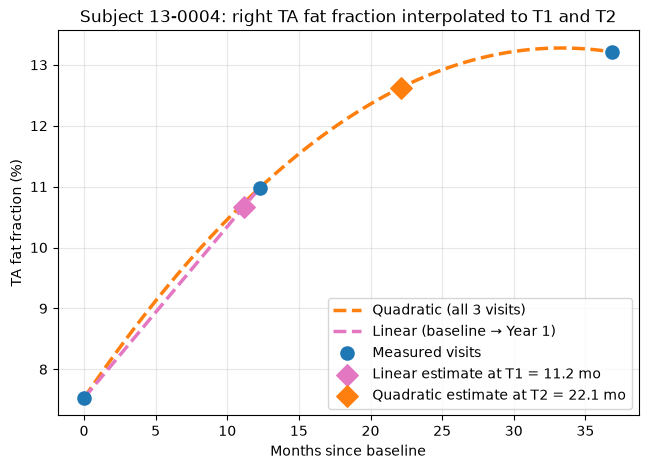

In [16]:
# Plot the measured visits, both interpolating functions, and both estimates
x_curve = np.linspace(lag_months[0], lag_months[-1], 200)   # only within the measured range

plt.figure(figsize=(7.5, 5))
plt.plot(x_curve, f_quadratic(x_curve), color="tab:orange", lw=2.5, linestyle="--",
         label="Quadratic (all 3 visits)")
plt.plot(lag_months[:2], ff_values[:2], color="tab:pink", lw=2.5, linestyle="--",
         label="Linear (baseline → Year 1)")
plt.scatter(lag_months, ff_values, color="tab:blue", s=90, zorder=4, label="Measured visits")
plt.scatter([T1], [estimate_T1], color="tab:pink", marker="D", s=120, zorder=5,
            label=f"Linear estimate at T1 = {T1:.1f} mo")
plt.scatter([T2], [estimate_T2], color="tab:orange", marker="D", s=120, zorder=5,
            label=f"Quadratic estimate at T2 = {T2:.1f} mo")
plt.title("Subject 13-0004: right TA fat fraction interpolated to T1 and T2")
plt.xlabel("Months since baseline")
plt.ylabel("TA fat fraction (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Figure 6: Linear and quadratic interpolation of FF for one subject
-
This figure shows subject 13-0004's measured right TA fat fraction at baseline, Year 1, and Year 2 (blue), the linear function through baseline and Year 1 (pink), the quadratic function through all three visits (orange), and the two interpolated estimates (diamonds). It is included to show how the interpolation works on real data before applying it to every subject. We can conclude that both estimates fall between the measured visits, so they are true interpolations, and that the hand calculation and `interp1d` give the same answers, which verifies our code. The quadratic curve bends and levels off because this subject's FF rose faster in the first year than afterward; near T1 the linear and quadratic curves almost overlap, but they would differ more at later times, which shows how the choice of method affects the estimate.

Next, we repeated the same steps for every subject and both legs in a loop. A subject needed baseline and Year 1 values for the linear T1 estimate, and all three visits for the quadratic T2 estimate; if any value was missing, we recorded `NaN` instead of letting the code crash. We saved the estimates to `interpolated_ff_estimates.csv` so they can be reused.

In [17]:
interp_rows = []

for _, row in fshd.iterrows():
    months = np.array([row[f"lag_months_{v}"] for v in visits], dtype=float)
    for side in ["R", "L"]:
        ff = np.array([row[ff_col(side, v)] for v in visits], dtype=float)

        # Linear estimate at T1: needs baseline + Year 1 with no missing values
        if not np.isnan(months[:2]).any() and not np.isnan(ff[:2]).any():
            ff_T1 = float(interp1d(months[:2], ff[:2], kind="linear")(T1))
        else:
            ff_T1 = np.nan

        # Quadratic estimate at T2: needs all three visits with no missing values
        # (visit times must also be strictly increasing; subject 1-0031 has Year 1 and Year 2 both at 24.3 months)
        if not np.isnan(months).any() and not np.isnan(ff).any() and np.all(np.diff(months) > 0):
            ff_T2 = float(interp1d(months, ff, kind="quadratic")(T2))
        else:
            ff_T2 = np.nan

        interp_rows.append({
            "subject_id": row["subject_id"],
            "side": side,
            "ff_baseline": ff[0],
            "ff_T1_linear": ff_T1,
            "ff_T2_quadratic": ff_T2,
        })

interp_df = pd.DataFrame(interp_rows)
interp_df.to_csv("interpolated_ff_estimates.csv", index=False)   # reusable output file

# How many subjects had enough data for each estimate
print(interp_df.groupby("side")[["ff_T1_linear", "ff_T2_quadratic"]].count())
interp_df.head(8).round(2)

      ff_T1_linear  ff_T2_quadratic
side                               
L               30               24
R               30               24


,subject_id,side,ff_baseline,ff_T1_linear,ff_T2_quadratic
0,1-0019,R,5.98,6.74,6.73
1,1-0019,L,8.34,10.87,8.42
2,1-0020,R,10.83,NaN,NaN
3,1-0020,L,15.03,NaN,NaN
4,1-0021,R,3.35,4.94,4.49
5,1-0021,L,5.34,5.81,6.17
6,1-0022,R,5.48,6.62,6.66
7,1-0022,L,6.63,8.31,8.44


Table 2: Interpolated FF estimates at T1 and T2 (first 8 rows)
-
This table shows each subject's measured baseline FF and their interpolated FF at T1 (linear) and T2 (quadratic) for each leg. It is included to show the output of the interpolation loop that the statistical test below uses. We can conclude that 30 subjects per leg had enough data for a T1 estimate and 24 per leg for a T2 estimate; the rest are `NaN` because of missing visits, which reduces our sample size.

**Statistical significance test.** To test whether FF changed significantly over a fixed amount of time, we compared each subject's baseline FF with their own interpolated FF at T1 and at T2. Because the same subjects are measured twice, this needs a **paired** test. We first checked whether the within-subject changes were normally distributed with the Shapiro–Wilk test (`stats.shapiro`). They were not (p < 0.05 for every comparison), so a paired t-test would not be appropriate, and we used the **Wilcoxon signed-rank test** (`stats.wilcoxon`), which does not assume normality. We used α = 0.05. The null hypothesis is that the median change in FF is zero.

In [18]:
test_rows = []

for side in ["R", "L"]:
    side_df = interp_df[interp_df["side"] == side]
    for label, col in [("T1 (linear)", "ff_T1_linear"), ("T2 (quadratic)", "ff_T2_quadratic")]:
        paired = side_df[["ff_baseline", col]].dropna()     # subjects with both values
        change = paired[col] - paired["ff_baseline"]          # positive = more fat

        shapiro_p = stats.shapiro(change).pvalue              # normality check on the changes
        wilcoxon_p = stats.wilcoxon(paired[col], paired["ff_baseline"]).pvalue   # paired, non-parametric

        test_rows.append({
            "side": side,
            "time_point": label,
            "n_subjects": len(paired),
            "mean_change_FF": change.mean(),
            "percent_increased": 100 * np.mean(change > 0),
            "shapiro_p": shapiro_p,
            "wilcoxon_p": wilcoxon_p,
            "significant_at_0.05": wilcoxon_p < 0.05,
        })

test_df = pd.DataFrame(test_rows)
test_df.round(4)

,side,time_point,n_subjects,mean_change_FF,percent_increased,shapiro_p,wilcoxon_p,significant_at_0.05
0,R,T1 (linear),30,0.9585,66.6667,0.0235,0.0175,True
1,R,T2 (quadratic),24,1.5192,75.0000,0.0193,0.0039,True
2,L,T1 (linear),30,1.6053,70.0000,0.0001,0.0006,True
3,L,T2 (quadratic),24,2.4672,83.3333,0.0042,0.0008,True


Table 3: Wilcoxon signed-rank test of FF change at T1 and T2
-
This table shows, for each leg and time point, the number of subjects, the mean change in FF from baseline, the percent of subjects whose FF increased, the Shapiro–Wilk p-value (normality check), and the Wilcoxon p-value. It is included because it is the statistical test of whether FF changed over a fixed time window. We can conclude that the changes were not normally distributed (all Shapiro p < 0.05), which is why we used the Wilcoxon test, and that FF increased significantly at both time points on both legs (all p < 0.05).

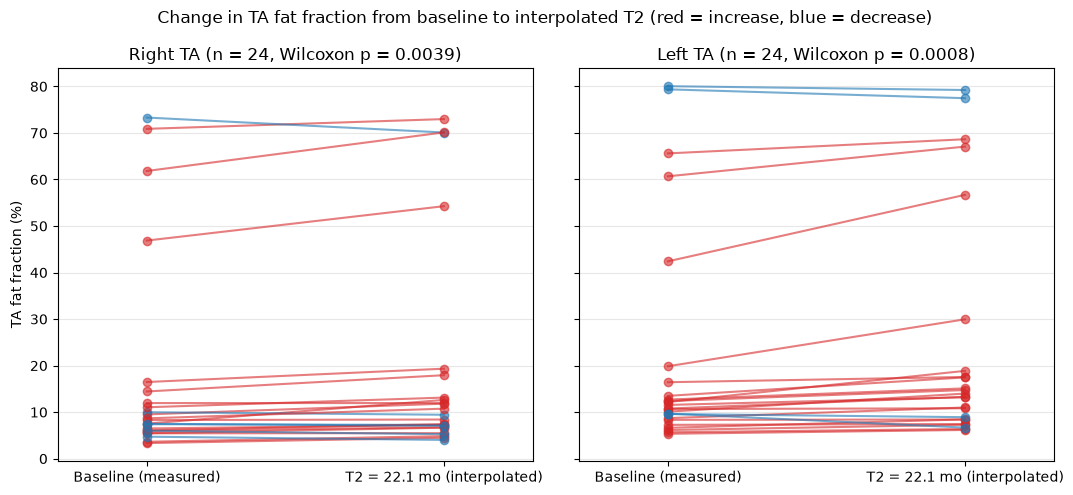

In [19]:
# Paired plot: each line connects one subject's baseline FF to their interpolated FF at T2
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

for ax, side in zip(axes, ["R", "L"]):
    paired = interp_df[interp_df["side"] == side][["ff_baseline", "ff_T2_quadratic"]].dropna()
    for _, row in paired.iterrows():
        color = "tab:red" if row["ff_T2_quadratic"] > row["ff_baseline"] else "tab:blue"   # red = FF went up
        ax.plot([0, 1], [row["ff_baseline"], row["ff_T2_quadratic"]], color=color, alpha=0.6, marker="o")

    p = test_df[(test_df["side"] == side) & (test_df["time_point"] == "T2 (quadratic)")]["wilcoxon_p"].iloc[0]
    side_name = "Right" if side == "R" else "Left"
    ax.set_title(f"{side_name} TA (n = {len(paired)}, Wilcoxon p = {p:.4f})")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Baseline (measured)", f"T2 = {T2:.1f} mo (interpolated)"])
    ax.set_xlim(-0.3, 1.3)
    ax.grid(True, axis="y", alpha=0.3)

axes[0].set_ylabel("TA fat fraction (%)")
fig.suptitle("Change in TA fat fraction from baseline to interpolated T2 (red = increase, blue = decrease)")
plt.tight_layout()
plt.show()

Figure 7: Baseline vs. interpolated T2 fat fraction for every subject
-
This figure connects each subject's measured baseline FF to their interpolated FF at T2 (22.1 months) for the right and left TA, colored red if FF increased and blue if it decreased, with the Wilcoxon p-value in each title. It is included because it shows the result of the statistical test together with the individual data behind it. We can conclude that FF increased in most subjects (75% right, 83% left) and that the increase was statistically significant on both legs at T2 (p = 0.0039 right, p = 0.0008 left) and at T1 (p = 0.018 right, p = 0.0006 left; see table above). The average increase is small (about 1.5–2.5 percentage points over 22 months), and the lines show that subjects with low baseline FF changed very little, a few subjects with moderate FF (about 20–60%) changed the most, and subjects already near 70–80% barely changed or even decreased slightly, likely because there is little muscle left to replace (a ceiling effect). This confirms, on an equal time scale for every subject, our earlier finding that FF detects disease progression within 2 years.

To check whether the same result holds for the functional measure, we repeated the exact same interpolation and test for dorsiflexion QMT (`dorsiflexion_qmt_R/L_baseline`, `_y1`, `_y2`): a linear estimate at T1, a quadratic estimate at T2, a Shapiro–Wilk normality check, and a paired Wilcoxon signed-rank test. For QMT, worsening means the force went **down**, so we report the percent of subjects whose strength decreased. One anomaly in the dataset is subject 1-0031, whose Year 1 and Year 2 visits are both recorded at 24.3 months; a quadratic cannot be fit through two points at the same time, so this subject was excluded from the T2 estimates (their FF at Year 2 was already missing).

In [20]:
qmt_test_rows = []

for side in ["R", "L"]:
    base, est_T1, est_T2 = [], [], []
    for _, row in fshd.iterrows():
        months = np.array([row[f"lag_months_{v}"] for v in visits], dtype=float)
        qmt = np.array([row[qmt_col(side, v)] for v in visits], dtype=float)
        base.append(qmt[0])
        # Same rules as FF: linear needs baseline + Year 1, quadratic needs all three visits
        ok_lin = not np.isnan(months[:2]).any() and not np.isnan(qmt[:2]).any()
        ok_quad = (not np.isnan(months).any() and not np.isnan(qmt).any()
                   and np.all(np.diff(months) > 0))   # visit times must be strictly increasing
        est_T1.append(float(interp1d(months[:2], qmt[:2], kind="linear")(T1)) if ok_lin else np.nan)
        est_T2.append(float(interp1d(months, qmt, kind="quadratic")(T2)) if ok_quad else np.nan)

    base = np.array(base)
    for label, est in [("T1 (linear)", np.array(est_T1)), ("T2 (quadratic)", np.array(est_T2))]:
        keep = ~np.isnan(base) & ~np.isnan(est)          # subjects with both values
        change = est[keep] - base[keep]                   # negative = weaker
        qmt_test_rows.append({
            "side": side,
            "time_point": label,
            "n_subjects": int(keep.sum()),
            "mean_change_QMT": change.mean(),
            "percent_weaker": 100 * np.mean(change < 0),
            "shapiro_p": stats.shapiro(change).pvalue,
            "wilcoxon_p": stats.wilcoxon(est[keep], base[keep]).pvalue,
            "significant_at_0.05": stats.wilcoxon(est[keep], base[keep]).pvalue < 0.05,
        })

qmt_test_df = pd.DataFrame(qmt_test_rows)
qmt_test_df.round(4)

,side,time_point,n_subjects,mean_change_QMT,percent_weaker,shapiro_p,wilcoxon_p,significant_at_0.05
0,R,T1 (linear),25,-0.3195,32.0000,0.0025,0.5872,False
1,R,T2 (quadratic),21,0.3954,33.3333,0.1924,0.3926,False
2,L,T1 (linear),25,-0.4466,52.0000,0.2882,0.9578,False
3,L,T2 (quadratic),21,-0.5990,52.3810,0.3610,0.8382,False


Table 4: Wilcoxon signed-rank test of QMT change at T1 and T2
-
This table shows the same test as Table 3 applied to dorsiflexion QMT: the number of subjects, the mean change in force from baseline (negative = weaker), the percent of subjects who got weaker, the Shapiro–Wilk p-value, and the Wilcoxon p-value. It is included so that both endpoints are tested the same way over the same time window. We can conclude that QMT did **not** change significantly at either time point on either leg (p = 0.39–0.96), and only about a third (right) to half (left) of subjects got weaker, which is close to chance. Some QMT changes passed the normality check (Shapiro p > 0.05), so a paired t-test would also have been allowed there, but we kept the Wilcoxon test for every comparison so the FF and QMT results are directly comparable. Together with Table 3, this shows with a formal test that FF is more sensitive to FSHD progression than dorsiflexion QMT over about 2 years.

**Assumptions, interpolation vs. extrapolation, and limitations**
- **Estimate, not a measurement:** no subject was actually scanned at 11.15 or 22.13 months. The values at T1 and T2 come from a model fitted through their real visits, so they carry the error of both the measurements and the model.
- **Assumptions:** the linear estimate assumes FF changed at a steady rate between baseline and Year 1. The quadratic estimate assumes FF follows a smooth curve through all three visits; with only three points, one noisy visit can bend the curve a lot.
- **Within range:** T1 and T2 were chosen as the earliest visits in the group, so every estimate lies between a subject's own measured visits. This is interpolation, not extrapolation.
- **Limitations:** subjects missing a visit were dropped (30 of 34 at T1, 24 of 34 at T2). Subjects with very late Year 2 visits (up to 42.8 months) have their T2 estimate placed far from any measurement, which adds uncertainty. Interpolation also cannot remove measurement noise, and we ran four tests (2 legs × 2 time points) without correcting for multiple comparisons. With a Bonferroni correction (0.05 / 4 = 0.0125), three of the four results stay significant; only the right leg at T1 (p = 0.018) would not.

## Conclusions:

**Which measures changed most consistently.** TA fat fraction (FF) was the most consistent measure. In the 34-subject dataset, FF increased in 67–84% of subjects (Figure 5 and Table 3), and when every subject was compared over the same 11.2 and 22.1 months using interpolation, the increase was statistically significant on both legs at both time points (Wilcoxon p = 0.0006–0.018). Dorsiflexion QMT did not change consistently: only about a third to a half of subjects got weaker, and none of the changes were significant (Table 4, p = 0.39–0.96). The single-subject MRI analysis showed the same pattern: subject UW_0020's mean TA FF increased at 7 of 8 locations between visits (Table 1).

**Which measures were most sensitive to location and visits.** FF was clearly the most sensitive. Its standardized response means were small-to-moderate (0.43–0.60) in every comparison, while QMT's were near zero (−0.22 to 0.06) (Figure 5). Along the muscle, FF was also very sensitive to location: in UW_0020 it ranged from about 17% to 84% at a single visit, and the largest increase happened in the middle of the TA (+25.5 points at 40%), while the end already near 80% fat barely changed (Figure 3, Table 1). This means where a slice is taken matters as much as when.

**Usefulness as biomarkers or exploratory endpoints.** Based on our results, we recommend **TA MRI fat fraction as the exploratory endpoint**, because it detects progression within about 2 years in a small group of patients, while dorsiflexion QMT does not. Published natural-history studies also link higher muscle FF to lower strength and function (References 7 and 9), so FF is not just a number without clinical meaning. We would keep QMT as a supporting functional measure rather than a main endpoint, because its visit-to-visit noise would require many more patients or longer trials to show a treatment effect.

**Evidence still needed.** Before FF could be used to judge whether a treatment works, we would need (1) larger natural-history cohorts to confirm how much FF normally changes per year, (2) evidence that slowing FF growth actually leads to patients keeping strength and function over time, (3) a defined minimal clinically important change in FF, (4) test–retest data showing how much FF varies between scans with no real change, and (5) standard rules for which muscles and slice locations to measure, since FF changes so much along the muscle.

**Ethical implications.** Choosing FF over QMT has trade-offs. FF is more sensitive, so trials could be smaller and shorter, exposing fewer patients to unproven drugs. However, patients care about what they can do (walking, climbing stairs, not tripping from foot drop), not about the fat content of a muscle on a scan. If a trial relied only on FF, a drug could be approved because it slows fat replacement without making patients feel or function better, or a drug that helps function could be missed. MRI is also expensive and not available everywhere, which could exclude patients who live far from research centers, have claustrophobia, or have metal implants, while QMT is cheap and portable. Subjects who already have very high FF (near 80%) barely changed, so an FF-only endpoint could overlook meaningful changes in the most severely affected patients. For these reasons, we recommend FF as the primary exploratory endpoint, always reported together with a functional measure like QMT so that patient-relevant outcomes are not ignored.


## Verification, Validation, Limitations and Future Work:

Our analysis allowed us to conclude that FF is more sensitive to disease progression and, therefore, would be a better candidate for use as an exploratory endpoint during clinical trials. We found that the standardized response means for muscle FF were 0.43–0.60 in every comparison, which is consistent with the published study "Longitudinal Study of MRI and Functional Outcome Measures in Facioscapulohumeral Muscular Dystrophy" (Wang et al., 2021). The article's results showed that muscle FF increased over a period of one year, while functional measures did not demonstrate significant change.

However, in "Five-Year Follow-Up Study on Quantitative Muscle Magnetic Resonance Imaging in FSHD," fat fraction increases were shown to have only weak correlations with overall disease outcomes, as demonstrated by a reported p-value of 0.3 (Vincenten et al., 2023). Therefore, we should not claim that muscle FF is the best indicator of disease progression or that dorsiflexion QMT has no utility in representing progression features of FSHD. Rather, we should support a multifaceted approach that uses both factors for analysis but emphasizes muscle FF slightly more than QMT in conveying disease progression for clinical trials.

Our work was limited by a variety of factors. We had a relatively small sample size of 34 subjects to work with. We also only had three visit data points available for each subject in the dataset, and some of those visit points were inconsistent or missing entirely. MRI measurements were limited by the fact that the data could have been collected differently for different subjects. Additionally, muscle fat fractions that are very high or very low can limit how discernible progression is for subjects. Changes could be more clearly illustrated by analyzing segmentation slices, which is a limitation because we only have information regarding a few locations along the muscle (10% to 80%). Biomarkers and analysis methods were limited by the missing values in the dataset and the fact that they cannot represent disease progression entirely, as FSHD has many different components that vary between individuals. Functional measures, such as dorsiflexion QMT, are limited by the general nature of the function being measured. For example, dorsiflexion QMT demonstrates the subject's overall ability to lift their foot, which can introduce inaccuracies in the data if subjects compensate for the weakening of certain muscles in their leg by using other muscles. All of these limitations can introduce potential sources of error in each part of the project, including the data, analysis, and conclusions.

If we had more time, we would improve the analysis by including more participants, adding more timepoints, comparing additional specific muscles within the limbs, and verifying the MRI data and how it was collected. Increasing the number of slices analyzed throughout the muscle would also improve the accuracy of the MRI analysis and, therefore, positively impact the validity of our results


## AI Usage Statement:

- We used Claude Code to help edit and tighten flow with the bullet points in the Disease Background and Data Set sections. We checked the drafts against the linked sources, and asked it to rewrite the text in a more natural voice and limit each point to a single citation.
- We used Claude Code to help debug the code in our graphs (especially the Wilcoxon significance tests), write comments, and improve our captions for the QMT vs. Fat Fraction Analysis, the Interpolation Analysis, and the Wilcoxon significance tests. It also found and fixed bugs in our MRI methodology code (Figure 3 was plotting percent instead of mm, the histogram y-axis was mislabeled, and the data path only worked on one computer). We verified the code by checking that the interpolation matched `interp1d`, re-running the whole notebook from top to bottom, and checking every caption against its figure.
- Claude Code helped, but it was not always right the first time. Its first captions described some figures more strongly than the data showed (for example, saying FF "drifted upward" when most lines were flat), so captions were revised after looking at the figures. It also found a data anomaly (subject 1-0031 has two visits at the same month) only after the code crashed.
- ChatGPT was also used for finding the published studies in the Verification and Validation Section.


## GitHub Repository Link:

https://github.com/alenabhilash03-beep/Module2BME2315


## References:

1. Deenen JCW, et al. Population-based incidence and prevalence of facioscapulohumeral dystrophy. *Neurology*. 2014. https://doi.org/10.1212/WNL.0000000000000797
2. Statland JM, Tawil R. Facioscapulohumeral muscular dystrophy. *Continuum (Minneap Minn)*. 2016. https://doi.org/10.1212/CON.0000000000000402
3. Preston MK, Tawil R, Wang LH. Facioscapulohumeral muscular dystrophy. *GeneReviews*. NCBI. https://www.ncbi.nlm.nih.gov/books/NBK1443/
4. Tawil R, et al. Evidence-based guideline summary: evaluation, diagnosis, and management of facioscapulohumeral muscular dystrophy. *Neurology*. 2015. https://doi.org/10.1212/WNL.0000000000001783
5. Tawil R, van der Maarel SM, Tapscott SJ. Facioscapulohumeral dystrophy: the path to consensus on pathophysiology. *Skeletal Muscle*. 2014. https://doi.org/10.1186/2044-5040-4-12
6. ClinicalTrials.gov. NCT05747924 (del-brax / AOC 1020 in FSHD). https://clinicaltrials.gov/study/NCT05747924
7. Wang LH, et al. MRI-informed muscle biopsies correlate MRI with pathology and DUX4 target gene expression in FSHD. *Neurology*. 2019. https://doi.org/10.1212/WNL.0000000000006836
8. Wang LH, et al. Longitudinal study of MRI and muscle biopsy in FSHD. *Annals of Clinical and Translational Neurology*. 2021. https://doi.org/10.1002/acn3.51440
9. Longitudinal study of MRI and functional outcome measures in facioscapulohumeral muscular dystrophy. PubMed. https://pubmed.ncbi.nlm.nih.gov/33691664/
10. Five-year follow-up study on quantitative muscle magnetic resonance imaging in facioscapulohumeral muscular dystrophy. PMC. https://pmc.ncbi.nlm.nih.gov/articles/PMC10401523/
11. BME 2315 course materials: `FSHD_TA_MRI_example_notebook.ipynb`, `Module2_interpolation_example.ipynb`, `Module2_FSHD_Dataset.csv`, and the `FSHD_TA_MRI_data_0020_TP1_TP2` README.


## NOTES FROM YOUR TEAM:


## QUESTIONS FOR YOUR TA:
